# Полнотекстовый поиск: грубый стемминг, биграммы, TF-IDF и BM25

В этой лекции:
- скачаем корпус русских текстов с разметкой «вопрос → абзац с ответом»;
- напишем токенизатор и **грубый стеммер** (первые 4 символа слова);
- добавим **биграммы стем** — пары соседних стем;
- построим обратный индекс и выполним булев поиск AND/OR;
- посчитаем TF-IDF руками и сверим с `TfidfVectorizer` из scikit-learn;
- реализуем BM25;
- измерим качество поиска разных вариантов на размеченных вопросах.

Всё работает на стандартном Python 3.10 + `numpy`, `scipy`, `pandas`, `scikit-learn`, `matplotlib`.
Никаких поисковых движков и морфологических словарей.

In [1]:
import math
import re
import time
import urllib.request
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

pd.set_option("display.max_colwidth", 120)
rng = np.random.default_rng(42)

## 1. Корпус: RuBQ 2.0

**RuBQ 2.0** (Russian Knowledge Base Questions) — открытый датасет:
- ~57 тыс. абзацев из русской Википедии — это наши документы для индексирования;
- ~2.9 тыс. вопросов на русском, для каждого известно, **в каких абзацах есть ответ**.

Разметка позволяет не «смотреть глазами», а измерять качество поиска.

- Оригинальный репозиторий: <https://github.com/vladislavneon/RuBQ> (лицензия CC BY-SA 4.0)
- Зеркало в формате Parquet (скачивается быстрее): <https://huggingface.co/datasets/d0rj/RuBQ_2.0>

Файлы скачиваются один раз в папку `../data/rubq`, дальше берутся из кэша.

In [2]:
DATA_DIR = Path("../data/rubq")
BASE_URL = "https://huggingface.co/datasets/d0rj/RuBQ_2.0/resolve/main/data/"
FILES = {
    "paragraphs.parquet": "paragraphs-00000-of-00001-d1f2ba7d11822891.parquet",
    "dev.parquet": "dev-00000-of-00001-d7e3040a344e1e68.parquet",
    "test.parquet": "test-00000-of-00001-d519841742f463e6.parquet",
}


def download_rubq(data_dir=DATA_DIR):
    data_dir.mkdir(parents=True, exist_ok=True)
    for local_name, remote_name in FILES.items():
        path = data_dir / local_name
        if path.exists():
            print(f"есть в кэше: {path} ({path.stat().st_size / 1e6:.1f} МБ)")
            continue
        print(f"скачиваю {remote_name} ...")
        urllib.request.urlretrieve(BASE_URL + remote_name, path)
        print(f"  сохранено: {path} ({path.stat().st_size / 1e6:.1f} МБ)")


download_rubq()

есть в кэше: ../data/rubq/paragraphs.parquet (24.3 МБ)
есть в кэше: ../data/rubq/dev.parquet (0.2 МБ)
есть в кэше: ../data/rubq/test.parquet (0.9 МБ)


### Документы

Каждый абзац имеет `uid` — его мы и будем возвращать из поиска.

In [3]:
paragraphs = pd.read_parquet(DATA_DIR / "paragraphs.parquet")
paragraphs = paragraphs.sort_values("uid").reset_index(drop=True)
assert (paragraphs["uid"].to_numpy() == np.arange(len(paragraphs))).all()

texts = paragraphs["text"].tolist()  # texts[i] — абзац с uid == i
print("документов:", len(texts))
paragraphs.head()

документов: 56952


,uid,ru_wiki_pageid,text
0,0,58311,"ЦСКА — советский и российский профессиональный хоккейный клуб из Москвы, выступающий в Континентальной хоккейной лиг..."
1,1,58311,"В первом сезоне в составе Континентальной хоккейной лиги ЦСКА выиграл дивизион Тарасова, но в плей-офф с трудом обыг..."
2,2,58311,"В межсезонье 1992 года «армейскую» команду покинули все лидеры, а Министерство обороны уже Российской Федерации, нах..."
3,3,58311,"Однако ни Тихонов, ни Гущин, не согласились с решениями Министра обороны, и своей отставки не признали. Сохраняя пра..."
4,4,58311,"ЦСКА Александра Волчкова сезон 1996/97 провел в Высшей лиге, и по итогам турнира завоевал путевку в Суперлигу. В сез..."


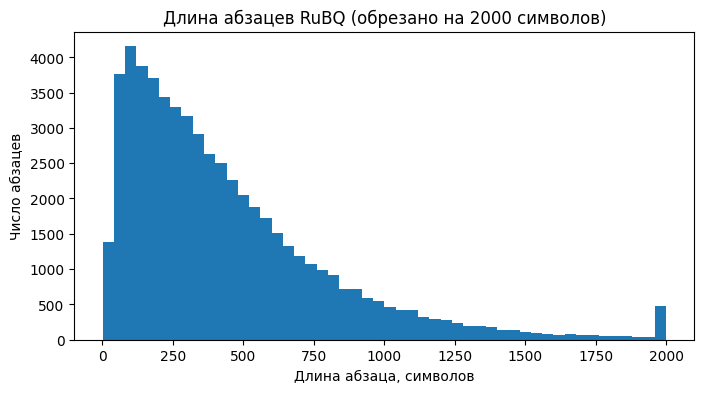

count    56952.0
mean       448.5
std        415.3
min          1.0
25%        172.0
50%        343.0
75%        600.0
max      11010.0
Name: text, dtype: float64


In [4]:
lengths_chars = paragraphs["text"].str.len()

plt.figure(figsize=(8, 4))
plt.hist(lengths_chars.clip(upper=2000), bins=50)
plt.title("Длина абзацев RuBQ (обрезано на 2000 символов)")
plt.xlabel("Длина абзаца, символов")
plt.ylabel("Число абзацев")
plt.show()

print(lengths_chars.describe().round(1))

### Вопросы

Возьмём dev-часть (580 вопросов). Поле `paragraphs_uids.with_answer` — абзацы, в которых есть ответ.
Это наши «правильные» документы (relevance judgments). Оставим только вопросы, у которых такие абзацы есть.

In [5]:
dev = pd.read_parquet(DATA_DIR / "dev.parquet")
dev["relevant"] = dev["paragraphs_uids"].map(lambda p: {int(x) for x in p["with_answer"]})
dev = dev[dev["relevant"].map(len) > 0].reset_index(drop=True)

print("вопросов с размеченными абзацами:", len(dev))
dev[["question_text", "answer_text", "relevant"]].head(8)

вопросов с размеченными абзацами: 444


,question_text,answer_text,relevant
0,Какой стране принадлежит знаменитый остров Пасхи?,Чили,"{10785, 10782, 10783}"
1,С какой музыкальной группой неразрывно связано имя Мика Джаггера?,'Роллинг Стоунз',"{53040, 53037, 53038, 53039}"
2,Где находится Летний сад?,Санкт-Петербург,"{25080, 25067}"
3,Какой город является столицей Туркмении?,Ашхабад,{14910}
4,В какой стране находится второй из самых высоких действующих вулканов с забавным названием Попокатепетль (5452 м)?,Мексика,"{53097, 53098}"
5,В каком виде спорта прославилась Курникова?,теннис,{53102}
6,В каком городе родился Вольфганг Амадей Моцарт?,Зальцбург,"{1746, 1743}"
7,В каком городе убили Джона Леннона?,Нью-Йорк,{7284}


In [6]:
example = dev.iloc[0]
print("Вопрос:", example["question_text"])
print("Ответ: ", example["answer_text"])
for uid in sorted(example["relevant"]):
    print(f"\n[{uid}]", texts[uid][:300])

Вопрос: Какой стране принадлежит знаменитый остров Пасхи?
Ответ:  Чили

[10782] Присутствуют также вооружённые силы Чили (преимущественно ВМФ). Действующая валюта на острове — чилийское песо (на острове в обороте также и доллары США). Остров Пасхи — беспошлинная зона, поэтому поступления в бюджет острова от уплаты налогов сравнительно невелики. В значительной степени он состоит

[10783] Первые чилийские корабли были замечены у Рапануи ещё в 1830-х годах, однако тесные торговые связи были налажены только в 1870-х годах. Победив Боливию и Перу в Тихоокеанской войне 1879—1883 годов, Чили приступила к активной колонизации земель. 9 сентября 1888 года капитан Поликарпо Торо Уртадо (Poli

[10785] остров Пасхи (нидерл. Paasch-Eyland; исп. Isla de Pascua), названный так голландским мореплавателем Якобом Роггевеном, потому что он открыл его в день Пасхи 1722 года.Очень часто остров Пасхи называют Рапануи (в переводе — «Большой Рапа»). Такое название остров получил благодаря таитянским мореплава

## 2. Токенизация

Простейший анализатор: нижний регистр, `ё → е`, выделение последовательностей «буквенных» символов.

Сразу выбрасываем **все токены короче 3 символов**: союзы и предлоги (`и`, `в`, `на`, `с`, `по`), частицы,
одиночные буквы и цифры. Это грубая замена списку стоп-слов: такие токены есть почти в каждом документе
и почти ничего не говорят о его теме. Платим за это потерей коротких значимых обозначений
(`ИИ`, `C3`, `5G`) и отрицания `не`.

Одинаковая обработка **обязательна** и для документов, и для запросов.

In [7]:
TOKEN_RE = re.compile(r"\w+")
MIN_TOKEN_LEN = 3  # всё, что короче, — выбрасываем


def tokenize(text):
    tokens = TOKEN_RE.findall(text.lower().replace("ё", "е"))
    return [t for t in tokens if len(t) >= MIN_TOKEN_LEN]


print(tokenize("Платёж E17 отклонён: верните деньги на карту!"))
print(tokenize("Какой стране принадлежит знаменитый остров Пасхи?"))
print(tokenize("В 1704 г. Пётр I и его сподвижники заложили сад на р. Неве"))

['платеж', 'e17', 'отклонен', 'верните', 'деньги', 'карту']
['какой', 'стране', 'принадлежит', 'знаменитый', 'остров', 'пасхи']
['1704', 'петр', 'его', 'сподвижники', 'заложили', 'сад', 'неве']


## 3. Грубый стемминг: первые 4 символа

Русский язык богат словоформами: `карта`, `карты`, `карту`, `картой` — для токенизатора это четыре
разных терма. Настоящий стеммер (Snowball) или лемматизатор (pymorphy) решает это по правилам/словарю.

Мы сделаем максимально грубо: **стема = первые `n` символов слова** (по умолчанию `n = 4`).
Это «обрезающий» стеммер (truncation stemmer).

In [8]:
STEM_LEN = 4


def stem(token, stem_len=STEM_LEN):
    return token if stem_len is None else token[:stem_len]


for word in ["карта", "карты", "карту", "картой", "картофель", "картина", "кит", "e17"]:
    print(f"{word:>10} → {stem(word)}")

     карта → карт
     карты → карт
     карту → карт
    картой → карт
 картофель → карт
   картина → карт
       кит → кит
       e17 → e17


Видно и плюсы, и минусы:
- словоформы `карта/карты/карту` склеились — **полнота (recall) растёт**;
- `картофель` и `картина` склеились с `картой` — **точность (precision) падает**;
- короткие слова (`кит`, `e17`) остаются как есть.

Посмотрим на корпусе, сколько разных слов попадает в одну стему.

In [9]:
word_counts = Counter()
for text in texts:
    word_counts.update(tokenize(text))

words_by_stem = defaultdict(list)
for word, count in word_counts.items():
    words_by_stem[stem(word)].append((count, word))

print("разных слов:", len(word_counts))
print("разных стем:", len(words_by_stem))
print(f"сжатие словаря: в {len(word_counts) / len(words_by_stem):.1f} раза")

разных слов: 290989
разных стем: 48587
сжатие словаря: в 6.0 раза


In [10]:
top_stems = sorted(words_by_stem.items(), key=lambda kv: -len(kv[1]))[:8]
for s, items in top_stems:
    frequent = [w for _, w in sorted(items, reverse=True)[:8]]
    print(f"{s!r:8} слов: {len(items):5}  например: {', '.join(frequent)}")

'пере'   слов:  2410  например: перед, переговоры, передачи, перешел, перевод, переход, переводе, переписи
'пред'   слов:  1300  например: представляет, предложил, представителей, представители, председатель, пределах, председателя, предложение
'прот'   слов:   587  например: против, протяжении, противника, протекает, протеста, протяженность, противников, прототипом
'прос'   слов:   581  например: просто, пространства, пространство, просьбой, просит, проспект, пространстве, просьбе
'анти'   слов:   555  например: античных, античности, античной, античные, антигитлеровской, антисемитизма, античного, анти
'полу'   слов:   540  например: получил, получила, получили, получить, полуострова, получает, получения, получив
'расп'   слов:   519  например: расположен, расположены, расположена, распространение, располагается, расположенный, распада, распространения
'пост'   слов:   507  например: постепенно, пост, постоянно, построен, поступил, построена, постройки, построены


Стема `пере` объединяет «перед», «переговоры» и «перевод», `пост` — «постепенно» и «построен».
Чтобы вернуть часть точности, можно добавить контекст: **биграммы стем**.

## 4. Биграммы стем

Биграмма — пара соседних стем: `остров Пасхи` → `остр_пасх`.
Отдельные стемы `остр` (остров, острый, остроумный…) и `пасх` (Пасха, пасхальный…) многозначны,
а их пара почти однозначно указывает на остров Пасхи.

Итоговый анализатор выдаёт список термов: униграммы стем и/или биграммы стем.

Это **гипотеза**: «биграммы улучшат поиск». В разделе 10 мы её проверим на размеченных вопросах.

In [11]:
def analyze(text, stem_len=STEM_LEN, ngrams="uni+bi"):
    stems = [stem(t, stem_len) for t in tokenize(text)]
    terms = []
    if "uni" in ngrams:
        terms += stems
    if "bi" in ngrams:
        terms += [f"{a}_{b}" for a, b in zip(stems, stems[1:])]
    return terms


query = "Какой стране принадлежит знаменитый остров Пасхи?"
print("слова:          ", analyze(query, stem_len=None, ngrams="uni"))
print("стемы:          ", analyze(query, ngrams="uni"))
print("биграммы стем:  ", analyze(query, ngrams="bi"))
print("стемы+биграммы: ", analyze(query))

слова:           ['какой', 'стране', 'принадлежит', 'знаменитый', 'остров', 'пасхи']
стемы:           ['како', 'стра', 'прин', 'знам', 'остр', 'пасх']
биграммы стем:   ['како_стра', 'стра_прин', 'прин_знам', 'знам_остр', 'остр_пасх']
стемы+биграммы:  ['како', 'стра', 'прин', 'знам', 'остр', 'пасх', 'како_стра', 'стра_прин', 'прин_знам', 'знам_остр', 'остр_пасх']


## 5. Обратный индекс на игрушечном примере

Прямое представление: документ → термы. **Обратное: терм → документы (posting list)**,
вместе с частотой терма в документе (TF).

In [12]:
toy_docs = {
    "A": "Возврат денег на карту",
    "B": "Оплата картой. Карта не принимается",
    "C": "Возврат товара в магазин",
    "D": "Картина маслом",
}

toy_postings = defaultdict(dict)
for doc_id, text in toy_docs.items():
    for term, tf in Counter(analyze(text)).items():
        toy_postings[term][doc_id] = tf

for term in sorted(toy_postings):
    print(f"{term:10} → {toy_postings[term]}")

возв       → {'A': 1, 'C': 1}
возв_дене  → {'A': 1}
возв_това  → {'C': 1}
дене       → {'A': 1}
дене_карт  → {'A': 1}
карт       → {'A': 1, 'B': 2, 'D': 1}
карт_карт  → {'B': 1}
карт_масл  → {'D': 1}
карт_прин  → {'B': 1}
мага       → {'C': 1}
масл       → {'D': 1}
опла       → {'B': 1}
опла_карт  → {'B': 1}
прин       → {'B': 1}
това       → {'C': 1}
това_мага  → {'C': 1}


Булев поиск: AND — пересечение posting lists, OR — объединение.
Обратите внимание: стемминг склеил `карту`, `картой`, `карта`… и, к сожалению, `картина`.

In [13]:
def boolean_search(postings, query, op="AND"):
    sets = [set(postings.get(term, {})) for term in analyze(query, ngrams="uni")]
    if not sets:
        return set()
    return set.intersection(*sets) if op == "AND" else set.union(*sets)


print("возврат AND карта:", sorted(boolean_search(toy_postings, "возврат карта", "AND")))
print("возврат OR карта: ", sorted(boolean_search(toy_postings, "возврат карта", "OR")))

возврат AND карта: ['A']
возврат OR карта:  ['A', 'B', 'C', 'D']


## 6. TF-IDF руками

- **TF** — сколько раз терм встречается в документе; берём сублинейный вариант `1 + ln(tf)`;
- **DF** — в скольких документах встречается терм;
- **IDF** — сглаженный вариант (как в scikit-learn): `idf(t) = ln((N + 1) / (df(t) + 1)) + 1`;
- вес `w(t, d) = tf'(t, d) · idf(t)`, затем L2-нормировка вектора документа.

Для L2-нормированных векторов скалярное произведение запроса и документа = косинусное сходство.

In [14]:
def toy_tfidf_vector(terms, idf):
    tf = Counter(t for t in terms if t in idf)
    vec = {t: (1 + math.log(c)) * idf[t] for t, c in tf.items()}
    norm = math.sqrt(sum(w * w for w in vec.values())) or 1.0
    return {t: w / norm for t, w in vec.items()}


n_toy = len(toy_docs)
toy_idf = {t: math.log((n_toy + 1) / (len(p) + 1)) + 1 for t, p in toy_postings.items()}
toy_vectors = {d: toy_tfidf_vector(analyze(text), toy_idf) for d, text in toy_docs.items()}



def toy_search(query):
    q_vec = toy_tfidf_vector(analyze(query), toy_idf)
    scores = {d: sum(w * vec.get(t, 0.0) for t, w in q_vec.items()) for d, vec in toy_vectors.items()}
    print("запрос:", query, "→ термы:", analyze(query))
    for d, s in sorted(scores.items(), key=lambda kv: -kv[1]):
        print(f"  {d} {s:.3f}  {toy_docs[d]}")
    return scores


toy_scores = toy_search("возвраты денег на карты")
_ = toy_search("вернуть деньги на карту")

запрос: возвраты денег на карты → термы: ['возв', 'дене', 'карт', 'возв_дене', 'дене_карт']
  A 1.000  Возврат денег на карту
  C 0.144  Возврат товара в магазин
  B 0.138  Оплата картой. Карта не принимается
  D 0.131  Картина маслом
запрос: вернуть деньги на карту → термы: ['верн', 'день', 'карт', 'верн_день', 'день_карт']
  B 0.435  Оплата картой. Карта не принимается
  D 0.411  Картина маслом
  A 0.318  Возврат денег на карту
  C 0.000  Возврат товара в магазин


Запрос «возвраты денег на карты» уверенно находит A: стемы `возв`, `дене`, `карт` и биграммы совпали,
хотя формы слов другие. Это сработал стемминг.

Запрос «вернуть деньги на карту» A уже не выделяет: `вернуть` → `верн`, а `возврат` → `возв`;
`деньги` → `день`, а `денег` → `дене`. Совпала только `карт` — и она же есть в B и D («картина»!).
Грубый стемминг помогает со словоформами, у которых совпадает начало, но не с чередованиями,
однокоренными словами с разным началом и синонимами.

### Сверка с scikit-learn

`TfidfVectorizer` с параметрами `sublinear_tf=True, smooth_idf=True, norm="l2"` реализует ту же формулу.
Свой анализатор передаём через `analyzer=`.

In [15]:
sk_vectorizer = TfidfVectorizer(analyzer=analyze, sublinear_tf=True, smooth_idf=True, norm="l2")
sk_docs = sk_vectorizer.fit_transform(toy_docs.values())
sk_q = sk_vectorizer.transform(["возвраты денег на карты"])
sk_scores = (sk_docs @ sk_q.T).toarray().ravel()

for d, s in zip(toy_docs, sk_scores):
    print(d, f"sklearn={s:.3f}  руками={toy_scores[d]:.3f}")

A sklearn=1.000  руками=1.000
B sklearn=0.138  руками=0.138
C sklearn=0.144  руками=0.144
D sklearn=0.131  руками=0.131


## 7. Индекс на реальном корпусе

На 57 тыс. документов словари Python-словарей занимают много памяти.
Используем разреженную матрицу «документ × терм» из `CountVectorizer` с **нашим** анализатором:

- строка матрицы — документ (прямой индекс);
- столбец в формате CSC — это и есть **posting list** терма (обратный индекс).

Токенизация и стемминг — наш Python-код; scikit-learn только раскладывает счётчики в матрицу.

In [16]:
def build_counts(texts, stem_len=STEM_LEN, ngrams="uni+bi"):
    vectorizer = CountVectorizer(analyzer=lambda text: analyze(text, stem_len, ngrams))
    counts = vectorizer.fit_transform(texts).tocsr().astype(np.float64)
    return vectorizer, counts


t0 = time.perf_counter()
count_vectorizer, counts = build_counts(texts)
print(f"построено за {time.perf_counter() - t0:.1f} с")
print("матрица документ×терм:", counts.shape, "ненулевых:", counts.nnz)
print(f"заполненность: {counts.nnz / (counts.shape[0] * counts.shape[1]):.6%}")

построено за 18.9 с
матрица документ×терм: (56952, 1476141) ненулевых: 5023760
заполненность: 0.005976%


### Posting lists и булев поиск

In [17]:
counts_csc = counts.tocsc()
vocab = count_vectorizer.vocabulary_


def postings(term):
    j = vocab.get(term)
    if j is None:
        return np.array([], dtype=np.int64)
    return counts_csc.indices[counts_csc.indptr[j]:counts_csc.indptr[j + 1]]


for term in ["остр", "пасх", "остр_пасх", "како"]:
    print(f"{term:10} df = {len(postings(term))}")

docs_and = np.intersect1d(postings("остр"), postings("пасх"))
docs_bigram = postings("остр_пасх")
print("\nостр AND пасх:", len(docs_and), "документов")
print("остр_пасх:    ", len(docs_bigram), "документов")
print("\nпример:", texts[docs_bigram[0]][:250])

остр       df = 1871
пасх       df = 69
остр_пасх  df = 23
како       df = 592

остр AND пасх: 25 документов
остр_пасх:     23 документов

пример: Крыса не является домашним животным, однако и она была завезена первыми поселенцами острова Пасхи, которые считали её деликатесом. После чёрных крыс, завезённых Хоту-Мату’а и его последователями, на острове появились уже серые крысы, завезённые европ


Чем реже терм, тем короче его posting list и тем сильнее он сужает поиск.
Биграмма `остр_пасх` даёт почти то же, что `остр AND пасх`, но без отдельного пересечения —
и дополнительно требует, чтобы слова стояли рядом.

### Распределение DF: закон Ципфа

Немногие термы встречаются почти везде (`года`, `кото` — «который»), а большинство — в 1–2 документах.
Союзы и предлоги мы уже выбросили, иначе они были бы на самом верху.

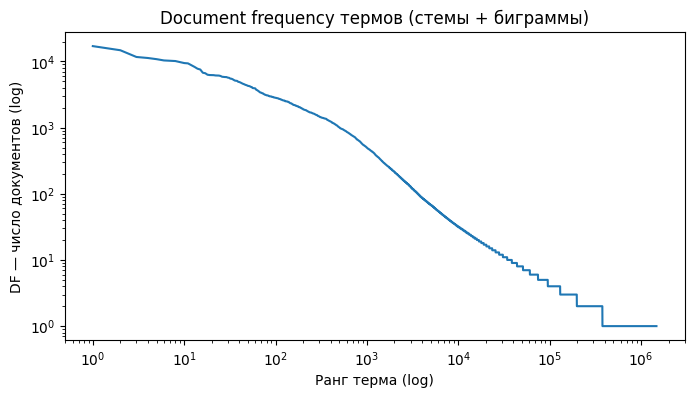

самые частые термы: ['года', 'кото', 'году', 'что', 'пред', 'пере', 'посл', 'как', 'был', 'его', 'для', 'перв', 'врем', 'такж', 'сост']
доля термов с df = 1: 74.4%


In [18]:
df = np.bincount(counts.indices, minlength=counts.shape[1])
df_sorted = np.sort(df)[::-1]

plt.figure(figsize=(8, 4))
plt.loglog(np.arange(1, len(df_sorted) + 1), df_sorted)
plt.title("Document frequency термов (стемы + биграммы)")
plt.xlabel("Ранг терма (log)")
plt.ylabel("DF — число документов (log)")
plt.show()

inv_vocab = np.array(count_vectorizer.get_feature_names_out())
print("самые частые термы:", list(inv_vocab[np.argsort(-df)[:15]]))
print(f"доля термов с df = 1: {(df == 1).mean():.1%}")

## 8. TF-IDF на всём корпусе

Считаем веса из матрицы счётчиков векторно — по тем же формулам, что и в разделе 6.

In [19]:
def tfidf_from_counts(counts):
    n_docs = counts.shape[0]
    df = np.bincount(counts.indices, minlength=counts.shape[1])
    idf = np.log((n_docs + 1) / (df + 1)) + 1

    weights = counts.copy()
    weights.data = (1 + np.log(weights.data)) * idf[weights.indices]  # sublinear tf · idf
    norms = np.sqrt(np.asarray(weights.multiply(weights).sum(axis=1)).ravel())
    weights = sparse.diags(1 / np.maximum(norms, 1e-12)) @ weights  # L2
    return weights.tocsr(), idf


def tfidf_query(query_counts, idf):
    q = query_counts.copy()
    q.data = (1 + np.log(q.data)) * idf[q.indices]
    norm = np.sqrt((q.data ** 2).sum()) or 1.0
    return q / norm


tfidf_docs, idf = tfidf_from_counts(counts)
print("tfidf:", tfidf_docs.shape)

tfidf: (56952, 1476141)


Проверим, что результат совпадает с `TfidfVectorizer` (на первых 3000 документах, чтобы не ждать).

In [20]:
sample = texts[:3000]
sk = TfidfVectorizer(analyzer=analyze, sublinear_tf=True, smooth_idf=True, norm="l2")
sk_matrix = sk.fit_transform(sample)

_, sample_counts = build_counts(sample)
my_matrix, _ = tfidf_from_counts(sample_counts)

# порядок столбцов в обоих случаях — сортировка термов по алфавиту
print("макс. расхождение весов:", abs(sk_matrix - my_matrix).max())

макс. расхождение весов: 2.7755575615628914e-16


### Функция поиска

Запрос проходит **тот же** анализатор и тот же словарь (`transform`, а не `fit`).
Термов вне словаря у запроса просто нет. Документы с нулевым скором не возвращаем.

In [21]:
def tfidf_search(query, k=5):
    q = tfidf_query(count_vectorizer.transform([query]), idf)
    scores = (tfidf_docs @ q.T).toarray().ravel()
    top = np.argsort(-scores)[:k]
    return [(int(i), float(scores[i])) for i in top if scores[i] > 0]


def show(results, max_chars=160):
    for uid, score in results:
        print(f"{score:7.3f}  [{uid}] {texts[uid][:max_chars]}")


show(tfidf_search("Какой стране принадлежит знаменитый остров Пасхи?"))

  0.165  [10785] остров Пасхи (нидерл. Paasch-Eyland; исп. Isla de Pascua), названный так голландским мореплавателем Якобом Роггевеном, потому что он открыл его в день Пасхи 172
  0.136  [16038] Переходящая дата — Пасха.
  0.135  [41526] В современной Полинезии широко распространены английский язык (на большинстве островов), французский язык (во Французской Полинезии, а также в Уоллис и Футуна, 
  0.132  [47768] В 2015 году норвежец Торгейр Хиграфф организовал экспедицию «Кон-Тики 2». На двух парусных плотах участники этой международной экспедиции, среди которых были че
  0.127  [8164] Так автор называет четвёртый материк. «Он был бы первой исторической страной, если бы на предания древних обращалось больше внимания, чем до сих пор». Знамениты


In [22]:
show(tfidf_search("кто написал роман война и мир"))

  0.204  [48599] Война и мир (фильм, 1967) — СССР, 1967.
  0.203  [48605] Война и мир (телесериал, 2016) — Великобритания, 2016.
  0.197  [48602] Война и мир (поэма) — поэма Владимира Маяковского.
  0.196  [48600] Война и мир (фильм, 1915) — Россия, 1915.
  0.185  [48598] Война и мир (фильм, 1956) — США, Италия, 1956.


## 9. BM25

BM25 отличается от TF-IDF двумя вещами:
- **насыщение TF** (параметр `k1`): десятое упоминание слова почти ничего не добавляет;
- **нормализация по длине** (параметр `b`): длинный документ чаще содержит слово случайно.

$$
\text{score}(q,d)=\sum_{t\in q}\ln\left(1+\frac{N-df_t+0.5}{df_t+0.5}\right)
\cdot\frac{tf_{t,d}\,(k_1+1)}{tf_{t,d}+k_1\left(1-b+b\frac{|d|}{avgdl}\right)}
$$

Посмотрим на насыщение TF для документа средней длины.

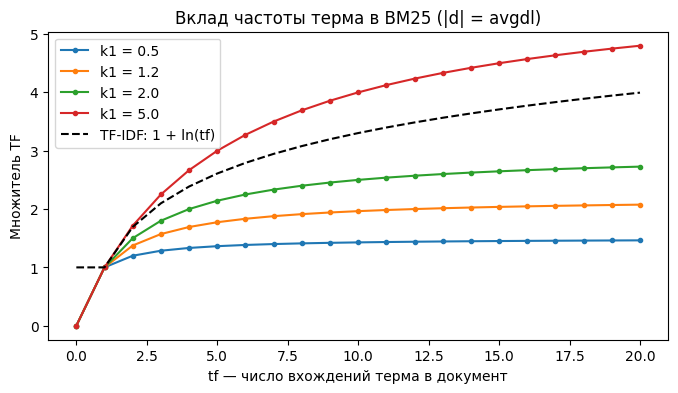

In [23]:
tf_grid = np.arange(0, 21)

plt.figure(figsize=(8, 4))
for k1 in [0.5, 1.2, 2.0, 5.0]:
    plt.plot(tf_grid, tf_grid * (k1 + 1) / (tf_grid + k1), marker=".", label=f"k1 = {k1}")
plt.plot(tf_grid, 1 + np.log(np.maximum(tf_grid, 1)) * (tf_grid > 0), "k--", label="TF-IDF: 1 + ln(tf)")
plt.title("Вклад частоты терма в BM25 (|d| = avgdl)")
plt.xlabel("tf — число вхождений терма в документ")
plt.ylabel("Множитель TF")
plt.legend()
plt.show()

Поскольку повторы термов в запросе BM25 (в нашем варианте) не учитывает, вес каждого (документ, терм)
можно посчитать заранее. Тогда скор = сумма весов документа по уникальным термам запроса,
то есть снова произведение разреженной матрицы на бинарный вектор запроса.

In [24]:
def bm25_from_counts(counts, k1=1.5, b=0.75):
    n_docs = counts.shape[0]
    df = np.bincount(counts.indices, minlength=counts.shape[1])
    idf = np.log(1 + (n_docs - df + 0.5) / (df + 0.5))

    doc_len = np.asarray(counts.sum(axis=1)).ravel()  # длина в термах
    avgdl = doc_len.mean()
    row_len = np.repeat(doc_len, np.diff(counts.indptr))  # длина документа для каждой ненулевой ячейки

    weights = counts.copy()
    tf = weights.data
    norm = 1 - b + b * row_len / avgdl
    weights.data = idf[weights.indices] * tf * (k1 + 1) / (tf + k1 * norm)
    return weights


def binary_query(query_counts):
    q = query_counts.copy()
    q.data[:] = 1.0
    return q


bm25_docs = bm25_from_counts(counts)


def bm25_search(query, k=5):
    q = binary_query(count_vectorizer.transform([query]))
    scores = (bm25_docs @ q.T).toarray().ravel()
    top = np.argsort(-scores)[:k]
    return [(int(i), float(scores[i])) for i in top if scores[i] > 0]


show(bm25_search("Какой стране принадлежит знаменитый остров Пасхи?"))

 32.888  [10785] остров Пасхи (нидерл. Paasch-Eyland; исп. Isla de Pascua), названный так голландским мореплавателем Якобом Роггевеном, потому что он открыл его в день Пасхи 172
 25.474  [47768] В 2015 году норвежец Торгейр Хиграфф организовал экспедицию «Кон-Тики 2». На двух парусных плотах участники этой международной экспедиции, среди которых были че
 25.154  [35775] По пути туда, на Таити, они узнали о войне между правящими кланами Рапа-Нуи. Многие миссионеры стали сомневаться в том, стоило ли им вообще плыть на остров Пасх
 25.128  [41526] В современной Полинезии широко распространены английский язык (на большинстве островов), французский язык (во Французской Полинезии, а также в Уоллис и Футуна, 
 24.248  [8164] Так автор называет четвёртый материк. «Он был бы первой исторической страной, если бы на предания древних обращалось больше внимания, чем до сих пор». Знамениты


In [25]:
show(bm25_search("кто написал роман война и мир"))

 34.530  [30505] Если не принимать в расчёт произведения детской литературы, роман «Война и мир» был самым издаваемым произведением художественной литературы в СССР за 1918—1986
 34.270  [30497] К работе над повестью Л. Н. Толстой возвращался восемь раз. В начале 1861 года он читал главы из романа «Декабристы», написанные в ноябре 1860 — начале 1861 год
 28.915  [9548] Русский писатель Иван Тургенев, антипод Толстого в жизни, оценивал писателя как «самого даровитого писателя во всей современной европейской литературе»; после в
 28.071  [9552] Наиболее известны такие произведения Толстого, как романы «Война и мир», «Анна Каренина», «Воскресение», автобиографическая трилогия «Детство», «Отрочество», «Ю
 26.736  [30494] «Война́ и мир» (рус. дореф. «Война и миръ») — роман-эпопея Льва Николаевича Толстого, описывающий русское общество в эпоху войн против Наполеона в 1805—1812 год


### Сверка с наивной реализацией через posting lists

Тот же BM25 «в лоб»: перебираем posting list каждого уникального терма запроса и накапливаем скор.
Именно так работает поиск по обратному индексу: документы без общих термов вообще не трогаются.

In [26]:
doc_len = np.asarray(counts.sum(axis=1)).ravel()
avgdl = doc_len.mean()
n_docs = counts.shape[0]


def bm25_naive(query, k=5, k1=1.5, b=0.75):
    scores = defaultdict(float)
    for term in set(analyze(query)):
        j = vocab.get(term)
        if j is None:
            continue
        start, end = counts_csc.indptr[j], counts_csc.indptr[j + 1]
        doc_ids, tfs = counts_csc.indices[start:end], counts_csc.data[start:end]
        idf_t = math.log(1 + (n_docs - len(doc_ids) + 0.5) / (len(doc_ids) + 0.5))
        for d, tf in zip(doc_ids, tfs):
            norm = 1 - b + b * doc_len[d] / avgdl
            scores[int(d)] += idf_t * tf * (k1 + 1) / (tf + k1 * norm)
    return sorted(scores.items(), key=lambda kv: -kv[1])[:k]


query = "Какой стране принадлежит знаменитый остров Пасхи?"
print("наивно:   ", [(d, round(s, 3)) for d, s in bm25_naive(query)])
print("матрично: ", [(d, round(s, 3)) for d, s in bm25_search(query)])

наивно:    [(10785, 32.888), (47768, 25.474), (35775, 25.154), (41526, 25.128), (8164, 24.248)]


матрично:  [(10785, 32.888), (47768, 25.474), (35775, 25.154), (41526, 25.128), (8164, 24.248)]


## 10. Оценка качества

Для каждого вопроса из dev получаем top-20 и смотрим, где в выдаче первый абзац с ответом.

- **Hit@k** (он же Recall@k для «хотя бы одного») — доля вопросов, у которых правильный абзац есть в top-k;
- **MRR@10** — среднее `1 / ранг` первого правильного абзаца (0, если его нет в top-10).

Для RAG особенно важен Hit@k при k = 5–10: именно столько абзацев обычно уходит в контекст LLM.

In [27]:
def top_k_batch(doc_matrix, query_matrix, k=20, batch_size=64):
    """Для каждой строки query_matrix — индексы top-k документов (только с ненулевым скором)."""
    doc_t = doc_matrix.T.tocsr()
    result = []
    for start in range(0, query_matrix.shape[0], batch_size):
        scores = (query_matrix[start:start + batch_size] @ doc_t).toarray()  # батч × документы
        for row in scores:
            top = np.argsort(-row, kind="stable")[:k]
            result.append(top[row[top] > 0])
    return result


def ranks_of_first_relevant(rankings, relevant_sets):
    ranks = []
    for ranking, relevant in zip(rankings, relevant_sets):
        hits = [pos for pos, uid in enumerate(ranking, start=1) if uid in relevant]
        ranks.append(hits[0] if hits else np.inf)
    return np.array(ranks, dtype=float)


def metrics_from_ranks(ranks):
    return {
        "Hit@1": np.mean(ranks <= 1),
        "Hit@5": np.mean(ranks <= 5),
        "Hit@10": np.mean(ranks <= 10),
        "Hit@20": np.mean(ranks <= 20),
        "MRR@10": np.mean(np.where(ranks <= 10, 1 / ranks, 0.0)),
    }


questions = dev["question_text"].tolist()
relevant = dev["relevant"].tolist()

Оценим уже построенный индекс «стемы-4 + биграммы».

In [28]:
q_counts = count_vectorizer.transform(questions)

q_tfidf = sparse.vstack([tfidf_query(q_counts.getrow(i), idf) for i in range(q_counts.shape[0])])
ranks_tfidf = ranks_of_first_relevant(top_k_batch(tfidf_docs, q_tfidf), relevant)

q_bin = q_counts.copy()
q_bin.data[:] = 1.0
ranks_bm25 = ranks_of_first_relevant(top_k_batch(bm25_docs, q_bin), relevant)

pd.DataFrame(
    {"TF-IDF": metrics_from_ranks(ranks_tfidf), "BM25": metrics_from_ranks(ranks_bm25)}
).T.round(3)

,Hit@1,Hit@5,Hit@10,Hit@20,MRR@10
TF-IDF,0.117,0.381,0.507,0.649,0.224
BM25,0.171,0.437,0.556,0.682,0.284


### Сравнение анализаторов

Переберём варианты: целые слова vs стемы-4; униграммы, биграммы и их объединение.
Для каждого варианта заново строим индекс (это занимает несколько секунд).

In [29]:
def evaluate_config(stem_len, ngrams, k1=1.5, b=0.75):
    vectorizer, doc_counts = build_counts(texts, stem_len, ngrams)
    query_counts = vectorizer.transform(questions)

    docs_tfidf, idf_c = tfidf_from_counts(doc_counts)
    queries_tfidf = sparse.vstack(
        [tfidf_query(query_counts.getrow(i), idf_c) for i in range(query_counts.shape[0])]
    )
    docs_bm25 = bm25_from_counts(doc_counts, k1=k1, b=b)
    queries_bin = query_counts.copy()
    queries_bin.data[:] = 1.0

    return {
        "TF-IDF": ranks_of_first_relevant(top_k_batch(docs_tfidf, queries_tfidf), relevant),
        "BM25": ranks_of_first_relevant(top_k_batch(docs_bm25, queries_bin), relevant),
    }


configs = [
    ("слова", None, "uni"),
    ("слова+биграммы", None, "uni+bi"),
    ("стемы-4", 4, "uni"),
    ("биграммы стем-4", 4, "bi"),
    ("стемы-4+биграммы", 4, "uni+bi"),
]

all_ranks = {}
for name, stem_len, ngrams in configs:
    t0 = time.perf_counter()
    for method, r in evaluate_config(stem_len, ngrams).items():
        all_ranks[(name, method)] = r
    print(f"{name:18} {time.perf_counter() - t0:5.1f} с")

results = pd.DataFrame({key: metrics_from_ranks(r) for key, r in all_ranks.items()}).T
results.index.names = ["анализатор", "метод"]
results.round(3)

слова                8.3 с


слова+биграммы      28.1 с


стемы-4              7.5 с


биграммы стем-4     17.0 с


стемы-4+биграммы    22.1 с


Hit@1  Hit@5  Hit@10  Hit@20  MRR@10
анализатор       метод                                       
слова            TF-IDF  0.144  0.340   0.446   0.570   0.227
                 BM25    0.203  0.410   0.525   0.606   0.292
слова+биграммы   TF-IDF  0.122  0.329   0.428   0.541   0.210
                 BM25    0.167  0.360   0.466   0.552   0.249
стемы-4          TF-IDF  0.142  0.408   0.550   0.691   0.247
                 BM25    0.239  0.568   0.691   0.770   0.378
биграммы стем-4  TF-IDF  0.077  0.234   0.313   0.374   0.146
                 BM25    0.095  0.250   0.320   0.369   0.160
стемы-4+биграммы TF-IDF  0.117  0.381   0.507   0.649   0.224
                 BM25    0.171  0.437   0.556   0.682   0.284

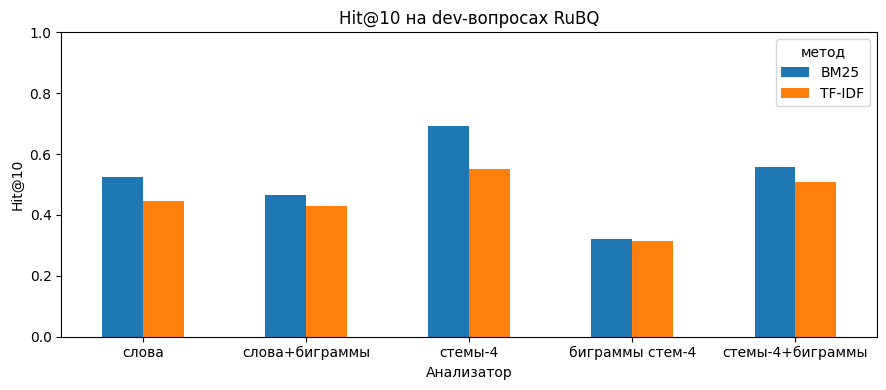

In [30]:
plot_df = results["Hit@10"].unstack("метод").loc[[c[0] for c in configs]]

ax = plot_df.plot.bar(figsize=(9, 4), rot=0)
ax.set_title("Hit@10 на dev-вопросах RuBQ")
ax.set_xlabel("Анализатор")
ax.set_ylabel("Hit@10")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

Что получилось:
- **грубый стемминг работает**: BM25 на стемах-4 заметно лучше, чем на целых словах, — для русского словоформы важны;
- **BM25 стабильно лучше TF-IDF** при любом анализаторе;
- **гипотеза про биграммы не подтвердилась**: добавление биграмм ухудшает результат, а только биграммы — худший вариант.

Почему так? Вопросы сформулированы иначе, чем статьи Википедии. Соседние слова вопроса
(`в каком`, `какой стране`, `в виде`) редко стоят рядом в нужном абзаце, зато случайно совпадают
с посторонними. Биграммы редки, поэтому у них **высокий IDF**, и одно случайное совпадение
перевешивает несколько совпавших стем. Единственная правильная проверка идеи — измерение.

### Может, биграммам нужен меньший вес?

Оставим индекс «стемы + биграммы», но в запросе дадим биграммам вес `w` вместо 1.
`w = 0` — биграммы не участвуют в скоре (но влияют на длину документа в BM25).

вес биграмм  0.0: Hit@10 = 0.691


вес биграмм 0.25: Hit@10 = 0.669


вес биграмм  0.5: Hit@10 = 0.651


вес биграмм 0.75: Hit@10 = 0.604


вес биграмм  1.0: Hit@10 = 0.556


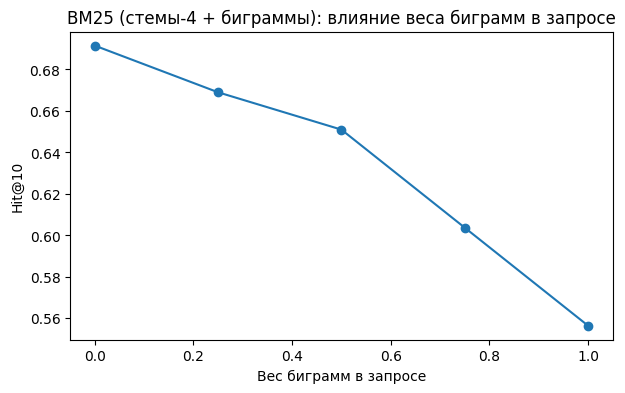

In [31]:
is_bigram = np.array(["_" in term for term in count_vectorizer.get_feature_names_out()])
q_main = count_vectorizer.transform(questions).tocsr()

bigram_weights = [0.0, 0.25, 0.5, 0.75, 1.0]
hit10_by_weight = []
for w in bigram_weights:
    q_weighted = q_main.copy()
    q_weighted.data = np.where(is_bigram[q_weighted.indices], w, 1.0)
    r = ranks_of_first_relevant(top_k_batch(bm25_docs, q_weighted), relevant)
    hit10_by_weight.append((r <= 10).mean())
    print(f"вес биграмм {w:4}: Hit@10 = {hit10_by_weight[-1]:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(bigram_weights, hit10_by_weight, marker="o")
plt.title("BM25 (стемы-4 + биграммы): влияние веса биграмм в запросе")
plt.xlabel("Вес биграмм в запросе")
plt.ylabel("Hit@10")
plt.show()

Монотонное падение: на этом корпусе и этих вопросах биграммы только мешают.
Это не значит, что биграммы бесполезны всегда: для коротких запросов-названий («остров Пасхи», «Летний сад»)
или для фразового поиска они полезны. Вывод зависит от данных — поэтому и нужна размеченная выборка.

### Hit@k в зависимости от k

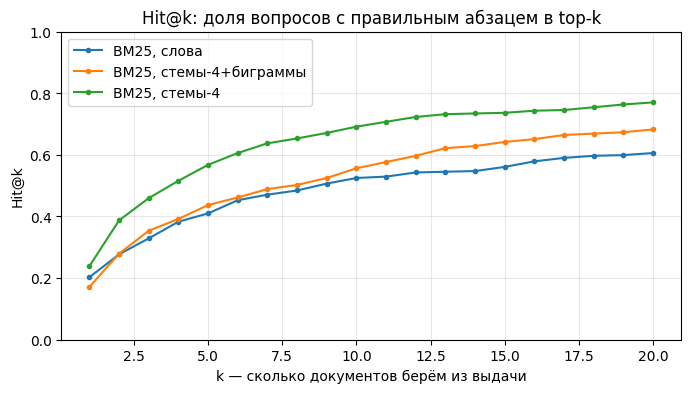

In [32]:
ks = np.arange(1, 21)

plt.figure(figsize=(8, 4))
for name in ["слова", "стемы-4+биграммы", "стемы-4"]:
    r = all_ranks[(name, "BM25")]
    plt.plot(ks, [(r <= k).mean() for k in ks], marker=".", label=f"BM25, {name}")
plt.title("Hit@k: доля вопросов с правильным абзацем в top-k")
plt.xlabel("k — сколько документов берём из выдачи")
plt.ylabel("Hit@k")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Какая длина стемы лучше?

`4` — произвольный выбор. Проверим 3…7 (BM25, только униграммы стем — лучший вариант выше).

stem_len = 3: Hit@10 = 0.608
stem_len = 4: Hit@10 = 0.691


stem_len = 5: Hit@10 = 0.655


stem_len = 6: Hit@10 = 0.644


stem_len = 7: Hit@10 = 0.626


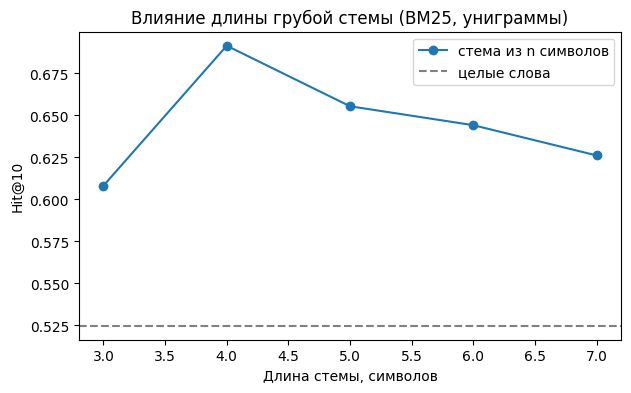

In [33]:
stem_lengths = [3, 4, 5, 6, 7]
hit10_by_len = []
for n in stem_lengths:
    if n == 4:
        r = all_ranks[("стемы-4", "BM25")]
    else:
        r = evaluate_config(n, "uni")["BM25"]
    hit10_by_len.append((r <= 10).mean())
    print(f"stem_len = {n}: Hit@10 = {hit10_by_len[-1]:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(stem_lengths, hit10_by_len, marker="o", label="стема из n символов")
plt.axhline((all_ranks[("слова", "BM25")] <= 10).mean(), color="gray", ls="--", label="целые слова")
plt.title("Влияние длины грубой стемы (BM25, униграммы)")
plt.xlabel("Длина стемы, символов")
plt.ylabel("Hit@10")
plt.legend()
plt.show()

Короткая стема склеивает слишком много разных слов, длинная — не склеивает словоформы.
Оптимум находится посередине; его стоит подбирать на **размеченной** выборке, а не на глаз.

### Лучший вариант: BM25 на стемах-4

Построим индекс лучшего анализатора отдельно — он пригодится для подбора параметров и разбора ошибок.

In [34]:
best_vectorizer, best_counts = build_counts(texts, stem_len=4, ngrams="uni")
best_bm25 = bm25_from_counts(best_counts)
best_queries = binary_query(best_vectorizer.transform(questions))
print("словарь:", best_counts.shape[1], "термов")


def best_search(query, k=5):
    q = binary_query(best_vectorizer.transform([query]))
    scores = (best_bm25 @ q.T).toarray().ravel()
    top = np.argsort(-scores)[:k]
    return [(int(i), float(scores[i])) for i in top if scores[i] > 0]


show(best_search("Какой город является столицей Туркмении?"))

словарь: 48587 термов
 20.860  [16845] Ашхаба́д (туркм. Aşgabat) — столица Туркмении, крупнейший административно-политический, промышленный, научный и культурный центр государства. Ашхабад является о
 18.308  [16847] В настоящее время в законодательных актах Туркмении (в их текстах на русском языке), в официальных средствах массовой информации Туркмении, на официальных сайта
 16.769  [16853] Большинство путешествий по Туркменистану начинаются со въезда в столицу страны Ашхабад или приморский город Туркменбашы. В Ашхабаде имеется современный междунар
 16.615  [16850] Ашхабад является одним из важнейших образовательных центров Туркмении, в городе сосредоточено значительное число объектов просвещения. По состоянию на учебный г
 15.762  [14911] Крупнейшие города Туркмении связаны с Ашхабадом и между собой авиасообщением. Самый крупный аэропорт находится в Ашхабаде, откуда совершаются регулярные междуна


### Параметры BM25: k1 и b

Небольшая сетка на лучшем анализаторе. Пересчитываем только веса — счётчики уже есть.

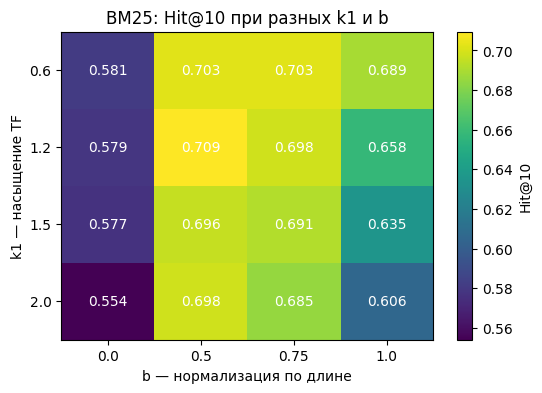

In [35]:
grid = {}
for k1 in [0.6, 1.2, 1.5, 2.0]:
    for b in [0.0, 0.5, 0.75, 1.0]:
        r = ranks_of_first_relevant(top_k_batch(bm25_from_counts(best_counts, k1, b), best_queries), relevant)
        grid[(k1, b)] = (r <= 10).mean()

grid_df = pd.Series(grid).unstack()
grid_df.index.name, grid_df.columns.name = "k1", "b"

plt.figure(figsize=(6, 4))
plt.imshow(grid_df.values, cmap="viridis", aspect="auto")
plt.colorbar(label="Hit@10")
plt.xticks(range(len(grid_df.columns)), grid_df.columns)
plt.yticks(range(len(grid_df.index)), grid_df.index)
for i in range(grid_df.shape[0]):
    for j in range(grid_df.shape[1]):
        plt.text(j, i, f"{grid_df.values[i, j]:.3f}", ha="center", va="center", color="white")
plt.title("BM25: Hit@10 при разных k1 и b")
plt.xlabel("b — нормализация по длине")
plt.ylabel("k1 — насыщение TF")
plt.show()

Внимание: подбирая параметры на dev и на нём же отчитываясь, мы переобучаемся.
Честная схема — подобрать на dev, итоговую цифру показать на test (`test.parquet`, ~2.3 тыс. вопросов).

## 11. Разбор ошибок

Посмотрим на вопросы, где лучший вариант (BM25, стемы-4) не нашёл размеченный абзац даже в top-10.

In [36]:
ranks_best = all_ranks[("стемы-4", "BM25")]
failed = np.where(ranks_best > 10)[0]
print(f"провалов: {len(failed)} из {len(ranks_best)}")

for i in failed[:5]:
    row = dev.iloc[i]
    top1 = best_search(row["question_text"], k=1)
    gold = min(row["relevant"])
    print("=" * 100)
    print("ВОПРОС:", row["question_text"], "| ОТВЕТ:", row["answer_text"])
    print("ТЕРМЫ ЗАПРОСА:", analyze(row["question_text"], ngrams="uni"))
    if top1:
        print(f"\nTOP-1 [{top1[0][0]}]:", texts[top1[0][0]][:250])
    print(f"\nНУЖНЫЙ [{gold}]:", texts[gold][:250])

провалов: 137 из 444
ВОПРОС: Где находится Летний сад? | ОТВЕТ: Санкт-Петербург
ТЕРМЫ ЗАПРОСА: ['где', 'нахо', 'летн', 'сад']

TOP-1 [17624]: Парк Культуры и отдыха — бывший Петровский сад (Летний сад) заложен в 1703 году. Старейший парк в России, в котором установлен памятник Петровскому заводу, имеется недействующий фонтан на месте пруда, который находился ранее при Дворце Петра Великого

НУЖНЫЙ [25067]: Ле́тний сад — парковый ансамбль, памятник садово-паркового искусства первой трети XVIII века в Центральном районе Санкт-Петербурга. Сад был заложен по повелению Петра I в 1704 году и первоначально был регулярным.
ВОПРОС: Какой город является столицей Туркмении? | ОТВЕТ: Ашхабад
ТЕРМЫ ЗАПРОСА: ['како', 'горо', 'явля', 'стол', 'турк']

TOP-1 [16845]: Ашхаба́д (туркм. Aşgabat) — столица Туркмении, крупнейший административно-политический, промышленный, научный и культурный центр государства. Ашхабад является отдельной административно-территориальной единицей Туркмении — городом с правами

Типичные причины провалов лексического поиска:
- **неполная разметка**: найденный абзац тоже содержит ответ, но не отмечен как правильный —
  метрики занижены, и это нормально для реальных датасетов;
- **разная лексика**: в вопросе одно слово, в абзаце — синоним или перифраз (`Туркмения` / `государство`);
- **однокоренные слова с разным началом** (`вернуть` / `возврат`) — стемминг по префиксу их не склеит;
- **частые слова перевешивают**: в вопросе мало редких термов, и выигрывает «похожий шум»;
- **ответ в абзаце без названия сущности**: «Он родился…» — имя объекта в соседнем абзаце.

Часть этих проблем решает **векторный (семантический) поиск** — следующий ноутбук.
А **гибридный поиск** объединит сильные стороны обоих подходов.

## Итоги

- Обратный индекс — структура «терм → документы»; в разреженной матрице это столбцы CSC.
- Грубый стемминг (префикс из 4 символов) — дешёвый способ справиться с русской морфологией.
- Биграммы стем выглядят разумно, но на вопросах RuBQ **ухудшают** качество: редкие биграммы получают
  высокий IDF и случайные совпадения перевешивают. Интуиция — это гипотеза, а не результат.
- TF-IDF — разреженный вектор и косинус; BM25 добавляет насыщение TF и нормализацию длины и здесь заметно лучше.
- Качество нужно **измерять** на размеченных запросах: Hit@k и MRR, а не судить по одному примеру.

## Задания

1. Сравните `MIN_TOKEN_LEN` = 1, 2, 3, 4 и список стоп-слов (`како`, `кото`, `явля`…). Как вернуть отрицание `не`?
2. Добавьте символьные триграммы внутри слов как дополнительные термы. Помогает ли это с опечатками?
3. Используйте биграммы не в скоре, а как бонус при переранжировании top-50 от BM25 на стемах. Стало ли лучше?
4. Подберите `stem_len`, `k1`, `b` на dev и посчитайте итоговые метрики на `test.parquet`.
5. Найдите 5 вопросов, где TF-IDF лучше BM25, и объясните почему.